In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
from scipy import optimize 
from astropy import units as u 
from astropy import constants as cnst
# import hunter2024mwmodel as h2024
import barframe
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})


In [4]:
# omega= -37.5
# bar1    =   h2024.coleman2020(**h2024.coleman_components)
# bar2    =   h2024.portail_component(**h2024.portail_bar_1)
# bar3    =   h2024.portail_component(**h2024.portail_bar_2)    
# pbar1   =   agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar2   =   agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar3   =   agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar    =   pbar1+pbar2+pbar3

# # the rest of the potetial 
# psagA       =   agama.Potential(**h2024.supermassiveblackhole)
# pnsc        =   agama.Potential(**h2024.nsc)
# pnsd1       =   agama.Potential(**h2024.NSD1,)
# pnsd2       =   agama.Potential(**h2024.NSD2)
# pdisk1      =   agama.Potential(**h2024.DISK1)
# pdisk2      =   agama.Potential(**h2024.DISK2)
# pgdisk1     =   agama.Potential(**h2024.GDISK1)
# pgdisk2     =   agama.Potential(**h2024.GDISK2)
# phalo       =   agama.Potential(**h2024.EINASTO)
# pot_total   =   agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)
# pot_total_rotating = agama.Potential(potential=pot_total, rotation = [[0,0],[1,omega]])

In [5]:
def rotate(posvel, angle):
    x, y, z, vx, vy, vz = posvel.T
    sina, cosa = numpy.sin(angle), numpy.cos(angle)
    return numpy.array([x*cosa-y*sina, x*sina+y*cosa, z, vx*cosa-vy*sina, vx*sina+vy*cosa, vz]).T

NOTE. Try and put omega in the potential and integrate in the inertial frame for creating the library. 

In [6]:
# TRY A SIMPLER MODEL FIRST 
bartype = "Ferrers"
barmass = 1e10
barScaleRadius = 5.5
axisRatioY = 0.35
axisRatioZ = 0.25

type_d1 = "MiyamotoNagai"
mass_d1 = 6e10/barmass
scaleRadius_d1 = 3.5/barScaleRadius
scaleHeight_d1 = 0.28/barScaleRadius

type_d2 = "MiyamotoNagai"
mass_d2 = 1e10/barmass
scaleRadius_d2 = 2.0/barScaleRadius
scaleHeight_d2 = 0.8/barScaleRadius

type_halo = "NFW"
mass_halo = 1e12/barmass
scaleRadius_halo = 20.0/barScaleRadius

In [7]:
unitM = barmass*u.Msun
unitL = barScaleRadius*u.kpc 
oldUnitG = (u.km/u.s)**2 * (u.kpc/u.Msun)
G=cnst.G.to(oldUnitG)
unitV = (G*unitM/unitL)**(1/2)
agama.setUnits(length=unitL.value, mass=unitM.value, velocity=unitV.value)   # kpc, Msun, km/s
bar     = agama.Potential(type="Ferrers",mass=1,scaleRadius=1,axisRatioY=axisRatioY,axisRatioZ=axisRatioZ)
disk1   = agama.Potential(type=type_d1,mass=mass_d1,scaleRadius=scaleRadius_d1, scaleHeight=scaleHeight_d1)
disk2   = agama.Potential(type=type_d2,mass=mass_d2,scaleRadius=scaleRadius_d2, scaleHeight=scaleHeight_d2)
halo    = agama.Potential(type=type_halo,mass=mass_halo,scaleRadius=scaleRadius_halo, )
potential = bar + disk1 + disk2 + halo

In [8]:
unitRotation    =  unitV/unitL
omegaOld        = 37.5 * u.km / u.kpc / u.s
omegaNew        = omegaOld.to(unitRotation)
omega           = omegaNew.value
potential_rotating = agama.Potential(potential=potential, rotation = [[0,0], [1, omega]])

In [52]:
norbits     =   int(1e4)
ics,mass    =   bar.sample(norbits, potential=potential, beta=1/2,kappa=1/10)

In [10]:
xl1, EL1 = barframe.lagrange_l1_energy(potential, omega)
xvzc,yvzc = barframe.xy_plane_zero_velocity_curve(potential,omega,EL1)

[None,
 Text(0, 0.5, '$\\rho$ [Ferrers]'),
 Text(0.5, 0, 'x $[a_{\\mathrm{bar}}]$')]

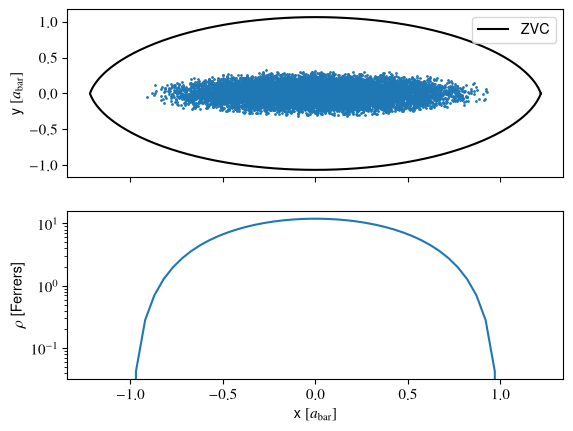

In [11]:
fig,axis=plt.subplots(2,1,sharex=True)
axis[0].scatter(ics[:,0],ics[:,1],s=1)
axis[0].plot(xvzc,yvzc,color="k",label="ZVC")
axis[0].set(ylabel=r"y $[a_{\mathrm{bar}}]$")
lgnd=axis[0].legend()
xs = numpy.linspace(-xl1,xl1)
pos = numpy.column_stack((xs,0*xs,0*xs))

axis[1].plot(numpy.linspace(-xl1,xl1), bar.density(pos));
axis[1].set(yscale="log",ylabel=r"$\rho$ [Ferrers]", xlabel=r"x $[a_{\mathrm{bar}}]$")

### Targets? 

1. First, just to the density naively, without regularisation with too few particles to see what happens 


**Questions**
- how do we get 704 bins for this binning scheme?

In [ ]:
# DensityCylindricalLinear
axisRatioY      =   axisRatioY
axisRatioZ      =   axisRatioZ
stripsPerPane   =   2

gridr           =   agama.nonuniformGrid(12, 0.1, xl1,)
gridz           =   agama.nonuniformGrid(12, 0.1, axisRatioZ,)
target_density  = agama.Target(type = "DensityClassicLinear",gridr = gridr, stripsPerPane = stripsPerPane, axisRatioY=axisRatioY, axisRatioZ=axisRatioZ)
times           =   10*potential.Tcirc(ics)


In [43]:
D,traj=agama.orbit(ic=ics,
                   potential=potential,
                   Omega=omega,
                   dtype=object,
                   time=times,
                   separateTime=True, 
                   targets=target_density)

10000 orbits complete (5247 orbits/s)


In [44]:
# the bar mass
total_bar_mass = bar.totalMass()
print("{:.2e}".format(total_bar_mass), "Msun")
# make each star the same mass
w = numpy.ones(len(ics)) * total_bar_mass / len(ics)
# get the discrete mass for each chunk
mass_discrete = D.T.dot(w)
mass_true = target_density(bar)

1.00e+00 Msun


[Text(0, 0.5, 'discretized'), Text(0.5, 0, 'true mass'), None]

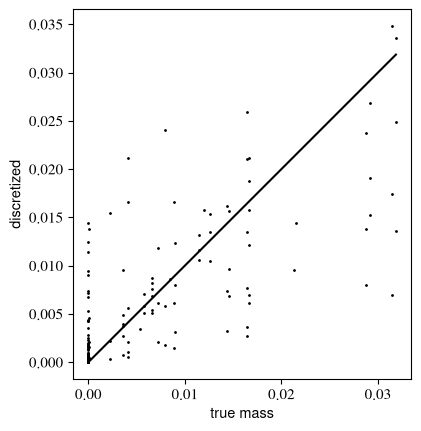

In [51]:
fig,axis = plt.subplots(1,1)
axis.scatter(mass_true,mass_discrete,s=1,color="k");
axis.plot([mass_true.min(), mass_true.max()],[mass_true.min(), mass_true.max()],zorder=10,color="k")
axis.set(ylabel="discretized", xlabel="true mass",aspect="equal")

In [46]:
data0 = numpy.ones((1, norbits))

try and make the constrain vector for the quadratic optimization 

In [47]:
constraints_density_uncertainty = 0.1 * mass_true

In [40]:
print((mass_true==0).sum(), )
print(len(mass_true))
print((D.sum(axis=0)==0).sum())

114
210
0


In [35]:
# solve the matrix equation for orbit weights
weights = agama.solveOpt(matrix=(data0, D.T), rhs=([total_bar_mass], mass_true),
    rpenl=([numpy.inf], numpy.ones(len(mass_true))*numpy.inf),
    xpenq=numpy.ones(norbits) )

Using a custom optimized KKT solver
numVariables=10000, numConstraints=211, numConsIneq=10000
     pcost       dcost       gap    pres   dres
 0:  3.5077e-03 -9.9635e-01  1e+04  1e+02  1e+02
 1:  3.5077e-03 -9.8260e-01  2e+02  2e+00  2e+00
 2:  3.5927e-03 -4.0469e-01  4e+01  4e-01  4e-01
 3:  4.7026e-03  8.0332e-01  2e+01  2e-01  2e-01
 4:  2.1592e-02  2.0487e+00  2e+01  1e-01  1e-01
 5:  2.8990e-02  4.1145e+00  1e+01  1e-01  1e-01
 6:  3.3547e-02  6.6831e+00  1e+01  8e-02  8e-02
 7:  3.3832e-02  8.7223e+00  1e+01  7e-02  7e-02
 8:  3.6331e-02  1.2971e+01  2e+01  7e-02  7e-02
 9:  3.7234e-02  1.6397e+01  2e+01  6e-02  6e-02
10:  4.0299e-02  2.0905e+01  2e+01  6e-02  6e-02
11:  5.1956e-02  2.9184e+01  2e+01  6e-02  6e-02
12:  5.9342e-02  3.9241e+01  2e+01  6e-02  6e-02
13:  6.5042e-02  5.4215e+01  3e+01  5e-02  5e-02
14:  6.9071e-02  7.3848e+01  3e+01  5e-02  5e-02
15:  7.2393e-02  9.3618e+01  4e+01  5e-02  5e-02
16:  8.0295e-02  1.2899e+02  4e+01  5e-02  5e-02
17:  8.2749e-02  1.4601e+

RuntimeError: Error in solveOpt(): quadraticOptimizationSolve: problem is infeasible

In [28]:
# try to find the weights, despite the fact thaty they're going to be very wrong
weights = agama.solveOpt(
    matrix=[data0, D.T], 
    rhs = [numpy.array([bar.totalMass()]),mass_true],
    rpenq = [numpy.array([numpy.inf]),2*constraints_density_uncertainty**-2 ])

/var/folders/y6/ylv42y_n4dg4m0hqhqfybl680000gq/T/ipykernel_27433/2495949188.py:5: RuntimeWarning: divide by zero encountered in power
  rpenq = [numpy.array([numpy.inf]),2*constraints_density_uncertainty**-2 ])


Using a custom optimized KKT solver
numVariables=10096, numConstraints=211, numConsIneq=10000
     pcost       dcost       gap    pres   dres
 0:  2.6276e-08 -9.9985e-01  1e+04  1e+02  1e+02
 1:  2.3019e-07 -9.8611e-01  2e+02  2e+00  2e+00
 2:  2.0682e-04 -4.0751e-01  4e+01  4e-01  4e-01
 3:  1.9004e-03  7.8328e-01  2e+01  2e-01  2e-01
 4:  5.0564e-03  1.6428e+00  2e+01  2e-01  2e-01
 5:  1.3496e-02  3.4253e+00  1e+01  1e-01  1e-01
 6:  2.6141e-02  5.4372e+00  1e+01  9e-02  9e-02
 7:  4.3456e-02  7.5385e+00  1e+01  8e-02  8e-02
 8:  7.1440e-02  1.0363e+01  2e+01  7e-02  7e-02
 9:  1.1229e-01  1.3609e+01  2e+01  7e-02  7e-02
10:  1.6109e-01  1.6785e+01  2e+01  6e-02  6e-02
11:  2.6685e-01  2.2071e+01  2e+01  6e-02  6e-02
12:  4.5067e-01  2.9769e+01  2e+01  6e-02  6e-02
13:  1.0029e+00  4.6336e+01  2e+01  5e-02  5e-02
14:  2.1740e+00  6.9262e+01  3e+01  5e-02  5e-02
15:  3.9830e+00  9.4070e+01  4e+01  5e-02  5e-02
16:  6.5198e+00  1.1991e+02  4e+01  5e-02  5e-02
17:  7.7343e+00  1.3085e+

RuntimeError: Error in solveOpt(): quadraticOptimizationSolve: problem is infeasible